# Customer Churn Prediction — Exploratory Data Analysis

Explore the IBM Telco Customer Churn dataset before modeling.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape}')
display(df.head())
df.info()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Data quality checks
Check missing values, duplicates, and convert TotalCharges to numeric.

In [3]:
display(df.isna().sum().sort_values(ascending=False))
print('Duplicate rows:', df.duplicated().sum())
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('TotalCharges missing after conversion:', df['TotalCharges'].isna().sum())
display(df[df['TotalCharges'].isna()][['customerID','tenure','MonthlyCharges','TotalCharges']])

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0
TotalCharges missing after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


## Target balance

,customers
Churn,
No,5174
Yes,1869


Churn rate: 26.54%


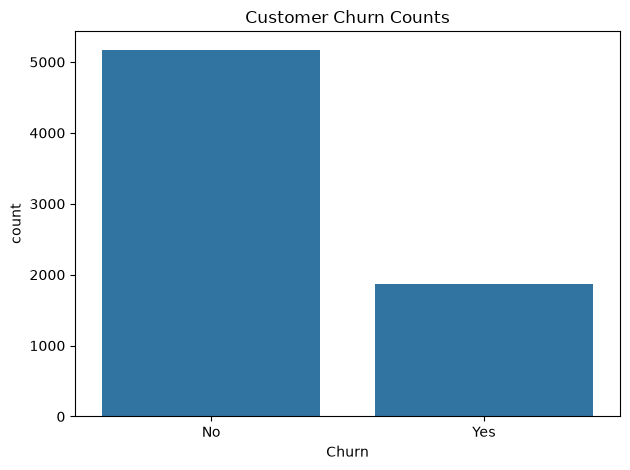

In [4]:
display(df['Churn'].value_counts().to_frame('customers'))
churn_rate = df['Churn'].eq('Yes').mean() * 100
print('Churn rate: {:.2f}%'.format(churn_rate))
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Counts')
plt.tight_layout()
plt.show()

## Numeric feature distributions

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


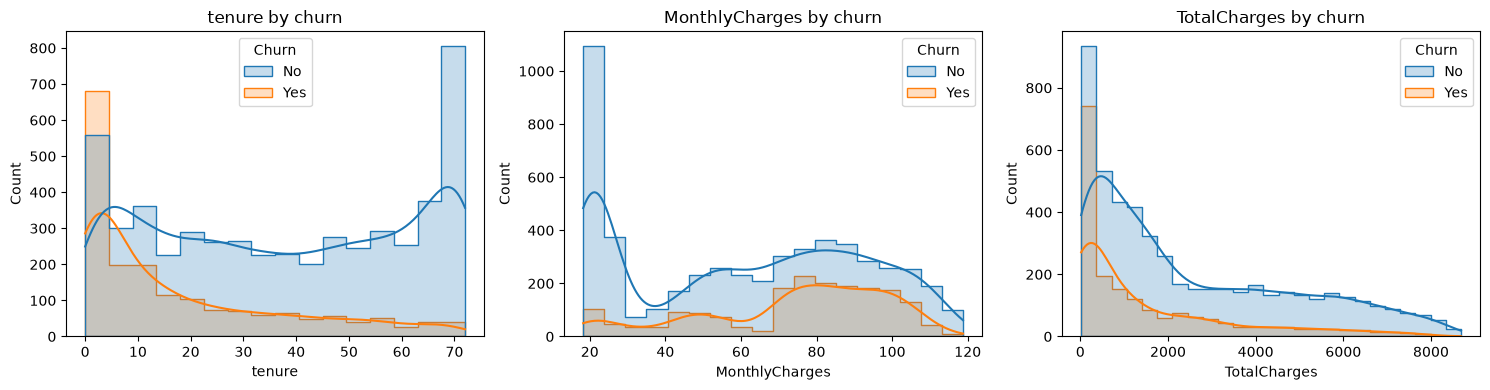

In [5]:
num_cols = ['tenure','MonthlyCharges','TotalCharges']
display(df[num_cols].describe().T)
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for col, ax in zip(num_cols, axes):
    sns.histplot(data=df, x=col, hue='Churn', kde=True, ax=ax, element='step')
    ax.set_title('{} by churn'.format(col))
plt.tight_layout()
plt.show()

## Churn by categorical features

,Churn rate (%)
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


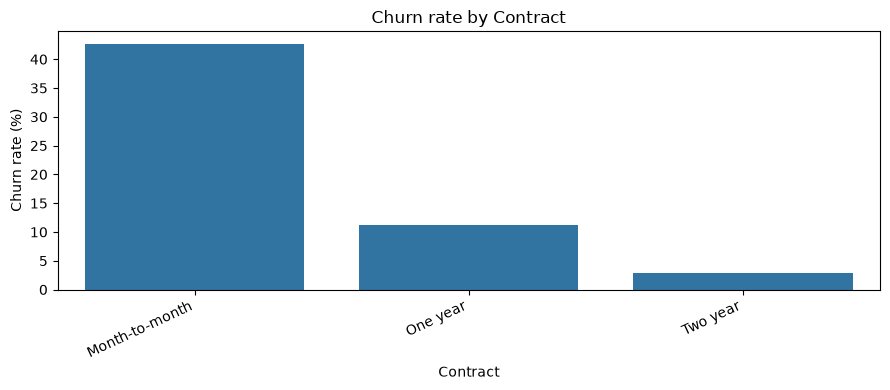

,Churn rate (%)
PaymentMethod,
Electronic check,45.285412
Mailed check,19.106700
Bank transfer (automatic),16.709845
Credit card (automatic),15.243101


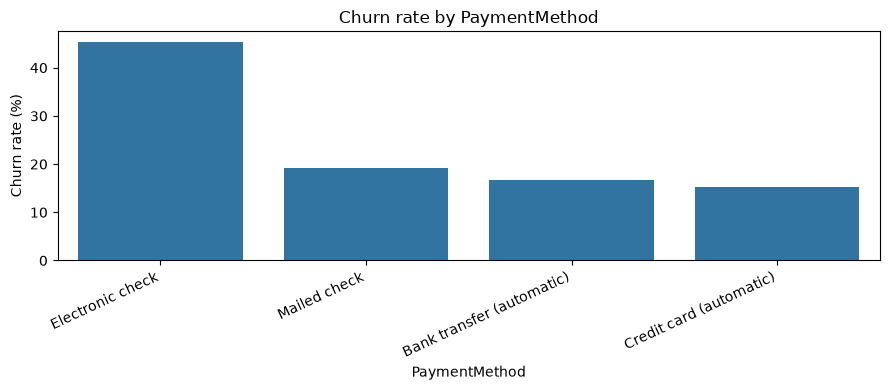

,Churn rate (%)
InternetService,
Fiber optic,41.892765
DSL,18.959108
No,7.404980


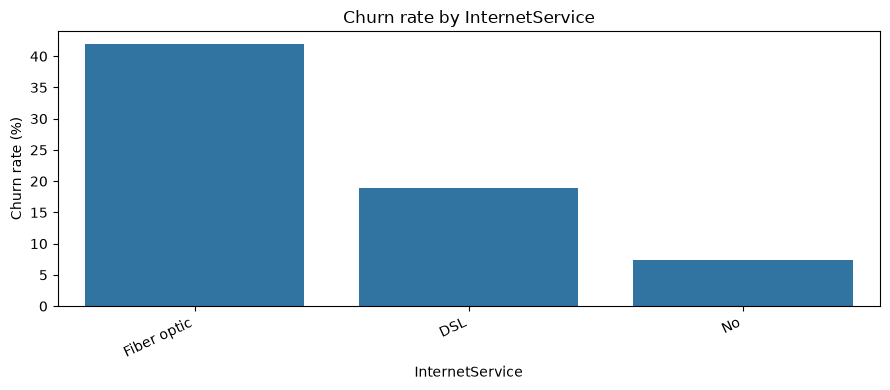

,Churn rate (%)
TechSupport,
No,41.635474
Yes,15.166341
No internet service,7.404980


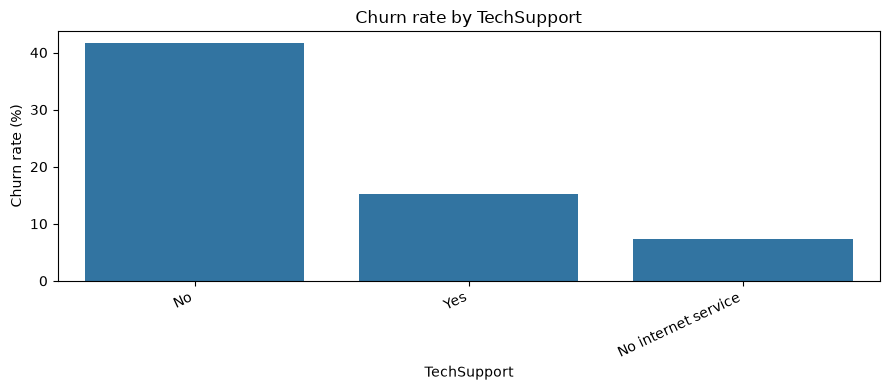

,Churn rate (%)
OnlineSecurity,
No,41.766724
Yes,14.611194
No internet service,7.404980


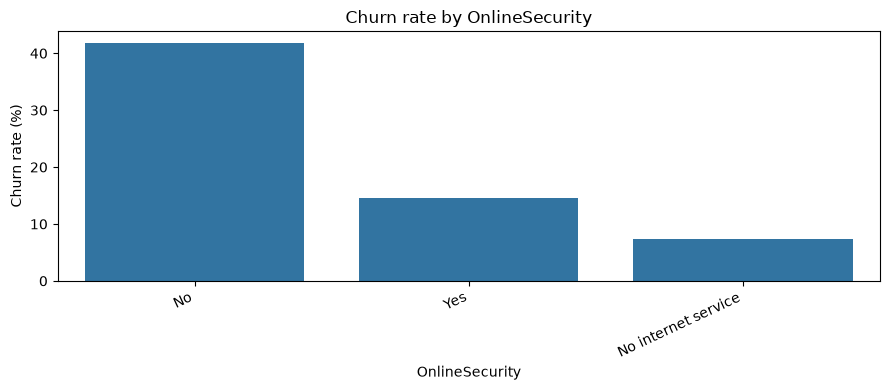

In [6]:
cat_cols = ['Contract','PaymentMethod','InternetService','TechSupport','OnlineSecurity']
for col in cat_cols:
    rate = df.groupby(col)['Churn'].apply(lambda s: s.eq('Yes').mean()).sort_values(ascending=False)
    display((rate*100).rename('Churn rate (%)').to_frame())
    plt.figure(figsize=(9,4))
    sns.barplot(x=rate.index.astype(str), y=rate.values*100)
    plt.title('Churn rate by {}'.format(col))
    plt.ylabel('Churn rate (%)')
    plt.xticks(rotation=25, ha='right')
    plt.tight_layout()
    plt.show()

## Numeric correlation

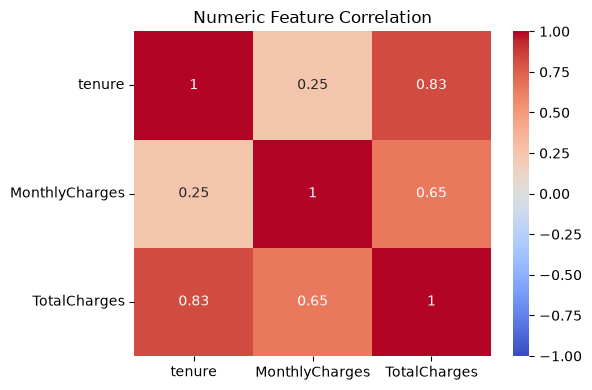

In [7]:
plt.figure(figsize=(6,4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Numeric Feature Correlation')
plt.tight_layout()
plt.show()

## Initial modeling notes
- Exclude customerID because it is an identifier.
- Convert TotalCharges to numeric; blank strings become missing values.
- Churn is the target. Consider class balance when selecting metrics.
- Split data before fitting preprocessing to avoid data leakage.

In [8]:
contract_churn = df.groupby('Contract')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

display(contract_churn)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

In [9]:
payment_churn = df.groupby('PaymentMethod')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
).sort_values(ascending=False)

display(payment_churn)

PaymentMethod
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn, dtype: float64

In [10]:
internet_churn = df.groupby('InternetService')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
).sort_values(ascending=False)

display(internet_churn)

InternetService
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn, dtype: float64

In [11]:
tenure_churn = df.groupby('Churn')['tenure'].mean()

display(tenure_churn)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [12]:
monthly_charges_churn = df.groupby('Churn')['MonthlyCharges'].mean()
display(monthly_charges_churn)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [13]:
total_charges_churn = df.groupby('Churn')['TotalCharges'].mean()
display(total_charges_churn)

Churn
No     2555.344141
Yes    1531.796094
Name: TotalCharges, dtype: float64

In [14]:
numeric_df = df.select_dtypes(include=['number'])

correlation = numeric_df.corr()

display(correlation.round(2))

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.00,0.02,0.22,0.10
tenure,0.02,1.00,0.25,0.83
MonthlyCharges,0.22,0.25,1.00,0.65
TotalCharges,0.10,0.83,0.65,1.00
